In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import requests
import os
from google.colab import userdata
from google.colab import drive
drive.mount('/content/drive')
import json
import glob
import cv2
from scipy import signal
from scipy.spatial.distance import cdist
from scipy.spatial import KDTree
from scipy import stats
from scipy.stats import t
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

Mounted at /content/drive


In [ ]:
tng_api_key = userdata.get('TNG_API_KEY')
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":tng_api_key}

In [ ]:
def get(path, params=None, out_filename=None):
    headers = {"api-key":tng_api_key}
    r = requests.get(path, params=params, headers=headers)
    r.raise_for_status()

    if out_filename is not None:
        with open(out_filename, 'wb') as f:
            f.write(r.content)
        return out_filename

    if r.headers['content-type'] == 'application/json':
        return r.json()

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename

    return r

In [ ]:
r = get(baseUrl)

for simulation in r['simulations']: #only get TNG50
    if simulation['name'] == 'TNG50-2':
        url = simulation['url']
        break

tng50 = get(url)

url = 'http://www.tng-project.org/api/TNG50-2/snapshots/z=1.9/'
snapshot = get(url)

sub_url = f"http://www.tng-project.org/api/TNG50-2/snapshots/{snapshot['number']}/subhalos/0/"
subhalo = get(sub_url)


--------------------------------------------------------------------------------

In [ ]:
sub_path = '/content/drive/MyDrive/docsTNG-2'

all_bhmdot = []
all_sfr = []

for folder_num in range(10):
    save_file_path = os.path.join(sub_path, f'sub{folder_num}.npz')

    if os.path.exists(save_file_path):
        loaded_data = np.load(save_file_path)
        all_bhmdot.append(loaded_data['bhmdot'])
        all_sfr.append(loaded_data['sfr'])
    else:
        print(f"File not found {folder_num}: {save_file_path}")

if all_bhmdot and all_sfr:
    final_bhmdot = np.concatenate(all_bhmdot)
    final_sfr = np.concatenate(all_sfr)

    print(f"Loaded the data from {len(all_bhmdot)} files.")

    print(f"First 10 elements of final_bhmdot: {final_bhmdot[:10]}")

    print(f"First 10 elements of final_sfr: {final_sfr[:10]}")
else:
    print("No data files were found or loaded.")


Loaded the data from 10 files.
First 10 elements of final_bhmdot: [0.00031151 0.00062199 0.00052268 0.0275541  0.00064812 0.00164843
 0.0041464  0.00103445 0.00080223 0.0243641 ]
First 10 elements of final_sfr: [136.024     34.4628     7.25007   56.9836     1.76587    3.10583
   3.91496    4.84131    0.471531   8.90733 ]


In [ ]:
vis_queries = [
    ("bfieldx", "partField=bfield_x&ctName=viridis&size=20&sizeType=kpc"),
    ("bfieldy", "partField=bfield_y&ctName=viridis&size=20&sizeType=kpc"),
    ("bfieldz", "partField=bfield_z&ctName=viridis&size=20&sizeType=kpc")
]
for i in range(100):
    print("i: ",i)
    for bfield_name, vis_query in vis_queries:
        bfield_url = f"http://www.tng-project.org/api/TNG50-2/snapshots/34/subhalos/{i}/vis.png?{vis_query}"
        try:
            get(bfield_url, out_filename=f'{bfield_name}_sub{i}.png')
        except Exception as e:
            print(f"sub{i} didn't work for {bfield_name}: {e}")

i:  0
i:  1
i:  2
i:  3
i:  4
i:  5
i:  6
i:  7
i:  8
i:  9
i:  10
i:  11
i:  12
i:  13
i:  14
i:  15
i:  16
i:  17
i:  18
i:  19
i:  20
i:  21
i:  22
i:  23
i:  24
i:  25
i:  26
i:  27
i:  28
i:  29
i:  30
i:  31
i:  32
i:  33
i:  34
i:  35
i:  36
i:  37
i:  38
i:  39
i:  40
i:  41
i:  42
i:  43
i:  44
i:  45
i:  46
i:  47
i:  48
i:  49
i:  50
i:  51
i:  52
i:  53
i:  54
i:  55
i:  56
i:  57
i:  58
i:  59
i:  60
i:  61
i:  62
i:  63
i:  64
i:  65
i:  66
i:  67
i:  68
i:  69
i:  70
i:  71
i:  72
i:  73
i:  74
i:  75
i:  76
i:  77
i:  78
i:  79
i:  80
i:  81
i:  82
i:  83
i:  84
i:  85
i:  86
i:  87
i:  88
i:  89
i:  90
i:  91
i:  92
i:  93
i:  94
i:  95
i:  96
i:  97
i:  98
i:  99


In [ ]:
min = -6000
max = 7500
bfield_means= []

for i in range(100):
    results = {}
    for bfield in ["bfieldx", "bfieldy", "bfieldz"]:
        img = cv2.imread(f"{bfield}_sub{i}.png")
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        cbar = img_rgb[100:-100, 1220:-140]
        area = img_rgb[100:-100, 200:1200]

        color = np.mean(cbar, axis=1)
        num = len(color)
        flat = area.reshape(-1,3)
        tree = KDTree(color)
        distances, indices = tree.query(flat)
        estimate = max - (indices/num)*(max-min)
        results[bfield] = estimate.reshape(area.shape[0], area.shape[1])

    bfield_mag = np.sqrt(results["bfieldx"]**2 + results["bfieldy"]**2 + results["bfieldz"]**2)
    mean_bfield = np.mean(bfield_mag)
    bfield_means.append(mean_bfield)

save = '/content/drive/MyDrive/docsTNG-2/bfield_means.txt'
np.savetxt(save, bfield_means)

In [ ]:
bfield_means_np = np.array(bfield_means)

num_subhalos = 100

bhmdot_for_plot = final_bhmdot[:num_subhalos]
sfr_for_plot = final_sfr[:num_subhalos]

<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_5071/1085863489.py:4: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\dot{m}_{BH}$')


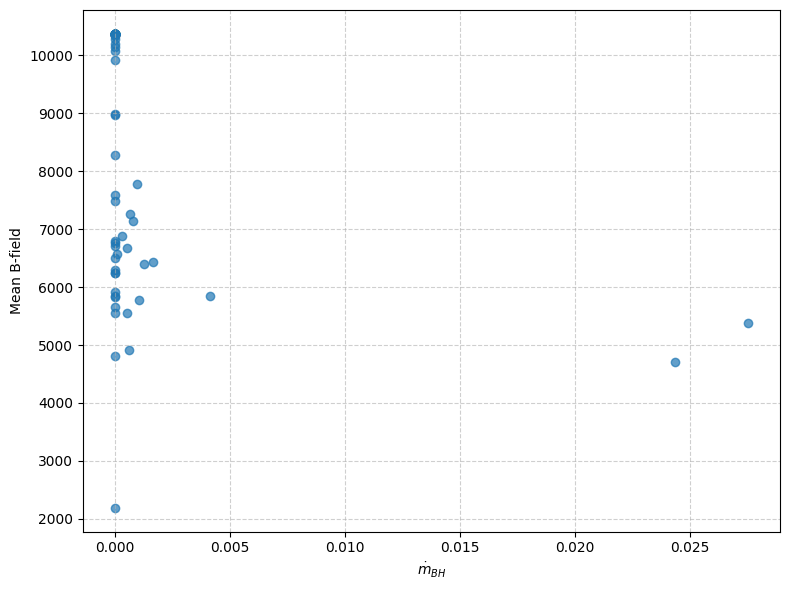

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter( bhmdot_for_plot,bfield_means_np, alpha=0.7)
plt.ylabel('Mean B-field')
plt.xlabel('$\dot{m}_{BH}$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_5071/2275339535.py:4: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\dot{m}_{BH}$')


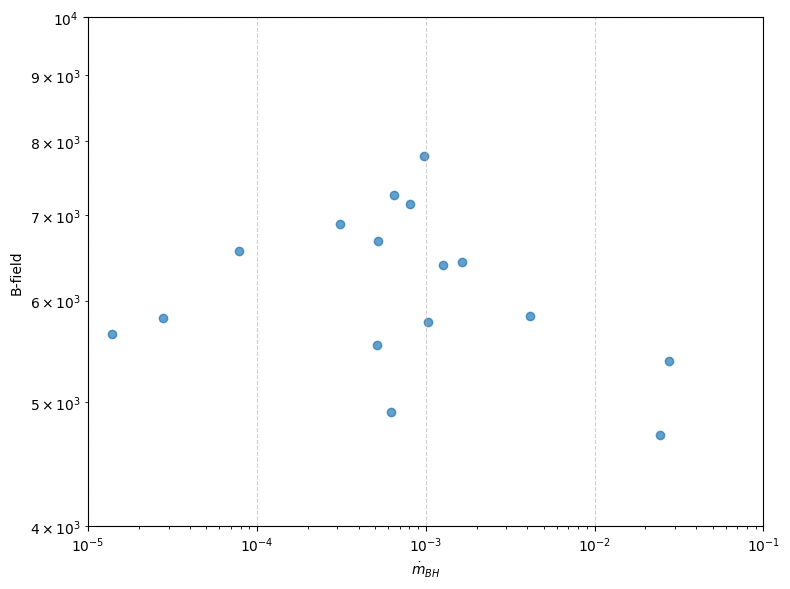

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(bhmdot_for_plot,bfield_means_np, alpha=0.7)
plt.ylabel('B-field')
plt.xlabel('$\dot{m}_{BH}$')
plt.xscale('log')\
# uncomment
plt.ylim(4*10e2, 10e3)
plt.xlim(10e-6, 10e-2)
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

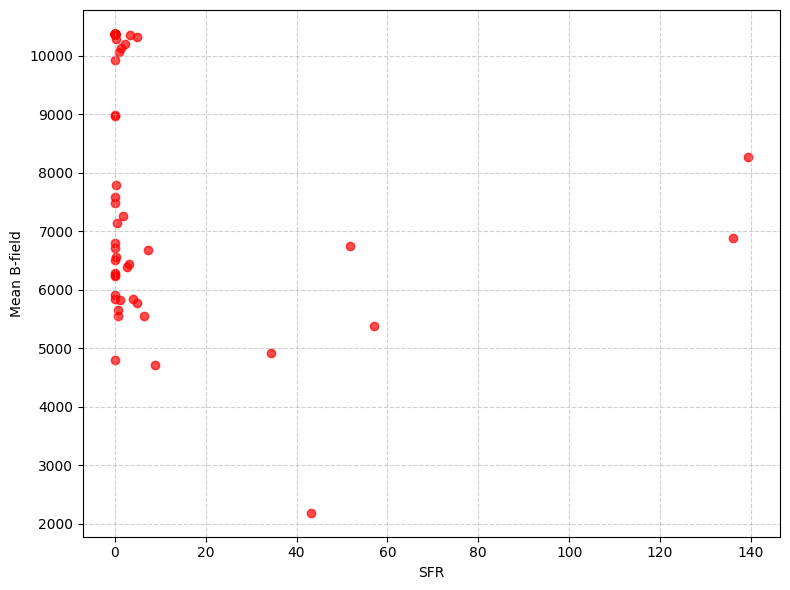

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(sfr_for_plot, bfield_means_np, alpha=0.7, color='red')
plt.xlabel('SFR')
plt.ylabel('Mean B-field')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

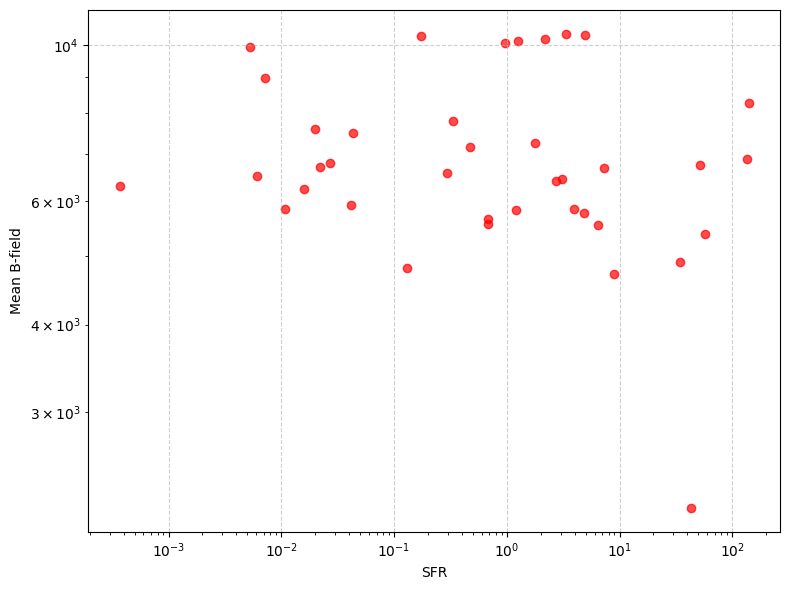

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(sfr_for_plot, bfield_means_np, alpha=0.7, color='red')
plt.xlabel('SFR')
plt.ylabel('Mean B-field')
plt.xscale('log')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
t_stat, p_val = stats.ttest_ind(final_bhmdot, final_sfr)

print(f"t_stat: {t_stat: .2f}")
print(f"p-val: {p_val: .3f}")

alpha = 0.5
if p_val < alpha:
    print(f"Since p-value ({p_val: .3f} is < than alpha ({alpha})), we reject the null hypothesis")
elif p_val > alpha:
    print(f"Since p-value ({p_val: .3f} is > than alpha ({alpha})), we accept the null hypothesis")

t_stat: -5.93
p-val:  0.000
Since p-value ( 0.000 is < than alpha (0.5)), we reject the null hypothesis


In [ ]:
t_stat, p_val = stats.ttest_ind(final_bhmdot, bfield_means)

print(f"t_stat: {t_stat: .2f}")
print(f"p-val: {p_val: .3f}")

alpha = 0.5
if p_val < alpha:
    print(f"Since p-value ({p_val: .3f} is < than alpha ({alpha})), we reject the null hypothesis")
elif p_val > alpha:
    print(f"Since p-value ({p_val: .3f} is > than alpha ({alpha})), we accept the null hypothesis")

t_stat: -448.66
p-val:  0.000
Since p-value ( 0.000 is < than alpha (0.5)), we reject the null hypothesis


In [ ]:
t_stat, p_val = stats.ttest_ind(final_sfr, bfield_means_np)

print(f"t_stat: {t_stat: .2f}")
print(f"p-val: {p_val: .3f}")

alpha = 0.5
if p_val < alpha:
    print(f"Since p-value ({p_val: .3f} is < than alpha ({alpha})), we reject the null hypothesis")
elif p_val > alpha:
    print(f"Since p-value ({p_val: .3f} is > than alpha ({alpha})), we accept the null hypothesis")

t_stat: -448.59
p-val:  0.000
Since p-value ( 0.000 is < than alpha (0.5)), we reject the null hypothesis
